# Major Project: Cataract Detection and Severity Preprocessing Pipeline

---

## 1. Project Overview
This notebook implements the complete data ingestion, curation, deduplication, quality filtering, and standardized partitioning pipeline for the **UncertaCat** cataract screening system.

### Core Objectives:
1. **Binary Cataract Screening:** Filters and standardizes retinal fundus photographs strictly into two target classes:
   * `0`: Normal (Healthy fundus with clear retinal media)
   * `1`: Cataract (Clinically diagnosed lens opacification)
2. **Continuous Cataract Severity Calibration:** Calibrates lens opacity on a continuous numerical scale from `0.0%` to `100.0%`:
   * Normal eyes across all repositories are calibrated at strictly `0.0%`.
   * CSDI expert-annotated images provide continuous clinical ground truth from `10.0%` to `100.0%`.
3. **Data Leakage Safeguard:** Enforces patient-level group partitioning so that bilateral images (left and right eyes) from any given subject remain strictly within the same split.
4. **Perceptual Deduplication:** Identifies and eliminates redundant fundus scans using difference hashing (dHash).
5. **Standardized Field of View (FOV) Auto-Cropping:** Centers the circular retina, strips dead black padding, preserves anatomical aspect ratio via symmetric square padding, and standardizes image dimensions to 224 x 224 pixels.
6. **Unified Partition Layout:** Populates `train/`, `val/`, `test/`, and `external_test/` subdirectories alongside a centralized `images/` directory and `metadata.csv` in a single execution.

---

## 2. Directory Hierarchy on Google Drive
All assets are generated inside:
`/content/drive/MyDrive/Major Project/preprocessed images/`

```text
Major Project/
└── preprocessed images/
    ├── metadata.csv          (Curated ground-truth table with splits and paths)
    ├── images/               (Central repository of all standardized images)
    ├── train/                (In-domain training split: 70%)
    ├── val/                  (In-domain validation split: 15%)
    ├── test/                 (In-domain internal test split: 15%)
    └── external_test/        (Held-out domain shift benchmark from RFMiD)
```

## Step 1: Environment Setup and Google Drive Mounting
Connects to Google Drive to persist the preprocessed dataset and installs necessary libraries.

In [12]:
from google.colab import drive
import os
import sys

drive.mount('/content/drive')

# Root Project Directories
DRIVE_ROOT = '/content/drive/MyDrive/Major Project'
OUTPUT_DIR = os.path.join(DRIVE_ROOT, 'preprocessed images')

IMAGES_DIR = os.path.join(OUTPUT_DIR, 'images')
TRAIN_DIR = os.path.join(OUTPUT_DIR, 'train')
VAL_DIR = os.path.join(OUTPUT_DIR, 'val')
TEST_DIR = os.path.join(OUTPUT_DIR, 'test')
EXT_TEST_DIR = os.path.join(OUTPUT_DIR, 'external_test')
METADATA_PATH = os.path.join(OUTPUT_DIR, 'metadata.csv')

RAW_DATA_DIR = '/content/raw_data'

# Ensure directories exist
for d in [OUTPUT_DIR, IMAGES_DIR, TRAIN_DIR, VAL_DIR, TEST_DIR, EXT_TEST_DIR, RAW_DATA_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"[INFO] Google Drive mounted successfully.")
print(f"[INFO] Output Directory: {OUTPUT_DIR}")

!pip install -q kaggle huggingface_hub opencv-python-headless pandas numpy pillow tqdm imagehash scikit-learn matplotlib


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[INFO] Google Drive mounted successfully.
[INFO] Output Directory: /content/drive/MyDrive/Major Project/preprocessed images


## Step 2: Kaggle Credentials Configuration
Configure Kaggle credentials to allow automated dataset downloading.
If `kaggle.json` is not present in `~/.kaggle/`, you will be prompted to upload it.

In [4]:
import os
import json
from google.colab import files

kaggle_dir = os.path.expanduser('~/.kaggle')
os.makedirs(kaggle_dir, exist_ok=True)
kaggle_json_path = os.path.join(kaggle_dir, 'kaggle.json')

if not os.path.exists(kaggle_json_path):
    print("[ACTION REQUIRED] Upload your kaggle.json file below:")
    uploaded = files.upload()
    if 'kaggle.json' in uploaded:
        with open(kaggle_json_path, 'wb') as f:
            f.write(uploaded['kaggle.json'])
        os.chmod(kaggle_json_path, 0o600)
        print("[SUCCESS] kaggle.json configured.")
    else:
        user = input("Kaggle Username: ").strip()
        key = input("Kaggle API Key: ").strip()
        with open(kaggle_json_path, 'w') as f:
            json.dump({"username": user, "key": key}, f)
        os.chmod(kaggle_json_path, 0o600)
        print("[SUCCESS] Kaggle credentials recorded.")
else:
    print("[INFO] Kaggle credentials found at ~/.kaggle/kaggle.json")


[INFO] Kaggle credentials found at ~/.kaggle/kaggle.json


## Step 3: Programmatic Dataset Ingestion
Downloads the three clinical retinal fundus repositories:
1. **ODIR-5K:** Comprehensive ocular disease benchmark with patient-level keywords.
2. **RFMiD:** Multi-center challenge dataset for cross-hospital evaluation.
3. **CSDI:** Expert-annotated continuous cataract severity dataset.

In [5]:
import subprocess
from pathlib import Path
from huggingface_hub import snapshot_download

raw_path = Path(RAW_DATA_DIR)

# 1. Ingest ODIR-5K
odir_dir = raw_path / "ODIR"
if not odir_dir.exists() or len(list(odir_dir.glob("*"))) == 0:
    print("[INFO] Fetching ODIR-5K from Kaggle API...")
    odir_dir.mkdir(parents=True, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "andrewmvd/ocular-disease-recognition-odir5k", "-p", str(odir_dir), "--unzip"], check=True)
    print("[SUCCESS] ODIR-5K uncompressed and ready.")
else:
    print("[INFO] ODIR-5K is already present.")

# 2. Ingest RFMiD
rfmid_dir = raw_path / "RFMiD"
if not rfmid_dir.exists() or len(list(rfmid_dir.glob("*"))) == 0:
    print("[INFO] Fetching RFMiD from Kaggle API...")
    rfmid_dir.mkdir(parents=True, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "andrewmvd/retinal-disease-classification", "-p", str(rfmid_dir), "--unzip"], check=True)
    print("[SUCCESS] RFMiD uncompressed and ready.")
else:
    print("[INFO] RFMiD is already present.")

# 3. Ingest CSDI
csdi_dir = raw_path / "CSDI"
if not csdi_dir.exists() or len(list(csdi_dir.glob("*"))) == 0:
    print("[INFO] Fetching CSDI from Hugging Face...")
    csdi_dir.mkdir(parents=True, exist_ok=True)
    snapshot_download(repo_id="RainyNight/CSDI", repo_type="dataset", local_dir=str(csdi_dir))
    print("[SUCCESS] CSDI acquired.")
else:
    print("[INFO] CSDI is already present.")


[INFO] Fetching ODIR-5K from Kaggle API...
[SUCCESS] ODIR-5K uncompressed and ready.
[INFO] Fetching RFMiD from Kaggle API...
[SUCCESS] RFMiD uncompressed and ready.
[INFO] Fetching CSDI from Hugging Face...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 193 files:   0%|          | 0/193 [00:00<?, ?it/s]

[SUCCESS] CSDI acquired.


## Step 4: Cataract-Specific Label Harmonization
Filters all records strictly into **Cataract** and **Normal**, discarding unrelated pathologies (e.g., pure glaucoma or pure diabetic retinopathy):
* **`label = 0` (Normal):** Clinically confirmed healthy fundus.
* **`label = 1` (Cataract):** Clinically diagnosed lens opacification.
* **`cataract_severity_pct` ($0.0\% - 100.0\%$):** Continuous severity percentage.
  - Normal images across all sources = `0.0%`.
  - CSDI severity score ($0.0 - 10.0$) scaled to percentage ($0.0\% - 100.0\%$).
* **`has_severity_gt`:** Flag set to 1 for samples with verified numerical severity.

In [6]:
import pandas as pd
import numpy as np
from pathlib import Path

records = []

# ==============================================================================
# 1. PARSE ODIR-5K (Strict Cataract vs Normal)
# ==============================================================================
print("[INFO] Filtering ODIR-5K for Cataract and Normal...")
odir_path = Path(RAW_DATA_DIR) / "ODIR"
csv_candidates = list(odir_path.glob("**/*full_df.csv")) or list(odir_path.glob("**/data.csv")) or list(odir_path.glob("**/*.csv"))

if csv_candidates:
    odir_df = pd.read_csv(csv_candidates[0])
    all_odir_imgs = {p.name: p for p in odir_path.glob("**/*.[jJ][pP][gG]") if "thumb" not in p.name.lower()}

    for _, row in odir_df.iterrows():
        pid = f"ODIR_{row.get('ID', row.name)}"

        for eye in ["Left", "Right"]:
            fundus_col = f"{eye}-Fundus"
            keyword_col = f"{eye}-Diagnostic Keywords"

            img_filename = str(row.get(fundus_col, "")).strip()
            keywords = str(row.get(keyword_col, "")).lower()

            if not img_filename or img_filename not in all_odir_imgs:
                continue

            img_path = all_odir_imgs[img_filename]

            is_cat = "cataract" in keywords or row.get('C', 0) == 1
            has_other_disease = any([row.get(k, 0) == 1 for k in ['D', 'G', 'H', 'A', 'M', 'O'] if k in row])
            is_norm = "normal fundus" in keywords and row.get('N', 0) == 1 and not has_other_disease

            if is_cat and not is_norm:
                label = 1
                class_name = "cataract"
                severity_pct = np.nan
                has_sev = 0
            elif is_norm and not is_cat:
                label = 0
                class_name = "normal"
                severity_pct = 0.0
                has_sev = 1
            else:
                # Exclude non-target ocular conditions (e.g. pure glaucoma, pure diabetes)
                continue

            records.append({
                "patient_id": pid,
                "eye_side": eye.lower(),
                "original_filename": img_filename,
                "raw_path": str(img_path),
                "source_dataset": "ODIR-5K",
                "label": label,
                "class_name": class_name,
                "cataract_severity_pct": severity_pct,
                "has_severity_gt": has_sev
            })

# ==============================================================================
# 2. PARSE RFMiD (Strict Cataract vs Normal)
# ==============================================================================
print("[INFO] Filtering RFMiD for Cataract and Normal...")
rfmid_path = Path(RAW_DATA_DIR) / "RFMiD"
rfmid_csvs = list(rfmid_path.glob("**/*Labels*.csv")) or list(rfmid_path.glob("**/*.csv"))
rfmid_imgs = {p.name: p for p in rfmid_path.glob("**/*.[pP][nN][gG]")} | {p.name: p for p in rfmid_path.glob("**/*.[jJ][pP][gG]")}

for csv_file in rfmid_csvs:
    df_rf = pd.read_csv(csv_file)
    id_col = df_rf.columns[0]

    cat_col = next((c for c in df_rf.columns if 'CAT' in c.upper()), None)
    risk_col = next((c for c in df_rf.columns if 'RISK' in c.upper()), None)

    if not (cat_col and risk_col):
        continue

    for _, row in df_rf.iterrows():
        img_id = str(row[id_col]).strip()
        matched_file = None
        for ext in ['.png', '.jpg', '.jpeg']:
            test_candidate = f"{img_id}{ext}"
            if test_candidate in rfmid_imgs:
                matched_file = rfmid_imgs[test_candidate]
                break
        if not matched_file:
            continue

        is_cat = row[cat_col] == 1
        is_norm = row[risk_col] == 0

        if is_cat:
            label = 1
            class_name = "cataract"
            severity_pct = np.nan
            has_sev = 0
        elif is_norm:
            label = 0
            class_name = "normal"
            severity_pct = 0.0
            has_sev = 1
        else:
            continue

        records.append({
            "patient_id": f"RFMID_{img_id}",
            "eye_side": "unknown",
            "original_filename": matched_file.name,
            "raw_path": str(matched_file),
            "source_dataset": "RFMiD",
            "label": label,
            "class_name": class_name,
            "cataract_severity_pct": severity_pct,
            "has_severity_gt": has_sev
        })

# ==============================================================================
# 3. PARSE CSDI (Severity Benchmark)
# ==============================================================================
print("[INFO] Parsing CSDI for Severity Benchmark...")
csdi_path = Path(RAW_DATA_DIR) / "CSDI"
csdi_csvs = list(csdi_path.glob("**/*.csv"))
csdi_imgs = {p.name: p for p in csdi_path.glob("**/*.[jJ][pP][gG]")} | {p.name: p for p in csdi_path.glob("**/*.[pP][nN][gG]")}

for csv_file in csdi_csvs:
    df_cs = pd.read_csv(csv_file)
    score_col = next((c for c in df_cs.columns if 'score' in c.lower()), None)
    name_col = next((c for c in df_cs.columns if 'name' in c.lower() or 'image' in c.lower() or 'id' in c.lower()), None)

    if score_col and name_col:
        for _, row in df_cs.iterrows():
            img_name = Path(str(row[name_col])).name
            if img_name not in csdi_imgs:
                continue

            img_path = csdi_imgs[img_name]
            score = float(row[score_col])

            label = 1 if score > 0.0 else 0
            class_name = "cataract" if label == 1 else "normal"
            severity_pct = round(np.clip(score * 10.0, 0.0, 100.0), 2)

            records.append({
                "patient_id": f"CSDI_{img_name.split('.')[0]}",
                "eye_side": "unknown",
                "original_filename": img_name,
                "raw_path": str(img_path),
                "source_dataset": "CSDI",
                "label": label,
                "class_name": class_name,
                "cataract_severity_pct": severity_pct,
                "has_severity_gt": 1
            })

df_raw = pd.DataFrame(records)
print(f"[INFO] Total harmonized cataract/normal records: {len(df_raw)}")
print(f"[INFO] Records with ground-truth severity percentage: {df_raw['has_severity_gt'].sum()}")
print(df_raw.groupby(['source_dataset', 'class_name']).size())


[INFO] Filtering ODIR-5K for Cataract and Normal...
[INFO] Filtering RFMiD for Cataract and Normal...
[INFO] Parsing CSDI for Severity Benchmark...
[INFO] Total harmonized cataract/normal records: 5192
[INFO] Records with ground-truth severity percentage: 4388
source_dataset  class_name
CSDI            cataract       185
                normal           2
ODIR-5K         cataract       804
                normal        4201
dtype: int64


## Step 5: Cross-Source Perceptual Deduplication
Calculates difference hashes (dHash) to identify and remove duplicate or re-encoded images across datasets.

In [7]:
import hashlib
import imagehash
from PIL import Image
from tqdm import tqdm

def compute_dhash(path_str):
    try:
        with Image.open(path_str) as img:
            return str(imagehash.dhash(img))
    except Exception:
        return None

tqdm.pandas(desc="Computing perceptual hashes")
df_raw['dhash'] = df_raw['raw_path'].progress_apply(compute_dhash)

df_raw = df_raw.dropna(subset=['dhash']).copy()
initial_count = len(df_raw)
df_dedup = df_raw.drop_duplicates(subset=['dhash'], keep='first').copy()
print(f"[SUCCESS] Deduplication complete. Removed {initial_count - len(df_dedup)} duplicate entries. Retained {len(df_dedup)} unique images.")


Computing perceptual hashes: 100%|██████████| 5192/5192 [03:41<00:00, 23.43it/s]

[SUCCESS] Deduplication complete. Removed 2884 duplicate entries. Retained 2308 unique images.


## Step 6: Patient-Aware Partitioning and Domain Shift Setup
* **Zero Patient Leakage:** Grouped by `patient_id` so left and right eyes of any subject remain in the same split.
* **In-Domain Partition (ODIR-5K + CSDI):**
  - Train: 70%
  - Validation: 15%
  - Internal Test: 15%
* **External Domain-Shift Benchmark (RFMiD):** Kept 100% held out to test cross-device generalization.

In [8]:
from sklearn.model_selection import GroupShuffleSplit

is_external = df_dedup['source_dataset'] == 'RFMiD'
df_external = df_dedup[is_external].copy()
df_external['split'] = 'external_test'

df_internal = df_dedup[~is_external].copy()

# In-domain split: 70% Train, 30% Temporary
gss1 = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=42)
train_idx, temp_idx = next(gss1.split(df_internal, groups=df_internal['patient_id']))

df_train = df_internal.iloc[train_idx].copy()
df_temp = df_internal.iloc[temp_idx].copy()

# Split Temporary into 50% Val, 50% Internal Test (15% each of in-domain total)
gss2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=42)
val_idx, test_idx = next(gss2.split(df_temp, groups=df_temp['patient_id']))

df_val = df_temp.iloc[val_idx].copy()
df_test = df_temp.iloc[test_idx].copy()

df_train['split'] = 'train'
df_val['split'] = 'val'
df_test['split'] = 'internal_test'

df_final = pd.concat([df_train, df_val, df_test, df_external], ignore_index=True)

# Verification check for zero patient overlap
train_patients = set(df_train['patient_id'])
val_patients = set(df_val['patient_id'])
test_patients = set(df_test['patient_id'])

overlap_tr_val = len(train_patients.intersection(val_patients))
overlap_tr_te = len(train_patients.intersection(test_patients))

assert overlap_tr_val == 0, "[ERROR] Patient leakage detected between Train and Validation!"
assert overlap_tr_te == 0, "[ERROR] Patient leakage detected between Train and Test!"
print("[SUCCESS] Zero patient leakage verified across all splits.")

print("\n[SUMMARY] Distribution by split and class:")
print(pd.crosstab(df_final['split'], df_final['class_name'], margins=True))


[SUCCESS] Zero patient leakage verified across all splits.

[SUMMARY] Distribution by split and class:
class_name     cataract  normal   All
split                                
internal_test        87     272   359
train               372    1229  1601
val                  75     273   348
All                 534    1774  2308


## Step 7: Anatomical FOV Auto-Cropping and Standardization
Isolates the circular retinal field of view, removes black padding, applies symmetric square padding to prevent distortion, and resizes to 224 x 224 pixels.

In [9]:
import cv2
import numpy as np

TARGET_SIZE = (224, 224)

def crop_and_standardize_fundus(img_bgr, target_size=TARGET_SIZE):
    if img_bgr is None:
        return None
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        return cv2.resize(img_bgr, target_size, interpolation=cv2.INTER_AREA)

    c = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(c)

    if w < 50 or h < 50:
        return cv2.resize(img_bgr, target_size, interpolation=cv2.INTER_AREA)

    cropped = img_bgr[y:y+h, x:x+w]
    ch, cw = cropped.shape[:2]
    max_side = max(ch, cw)
    square_img = np.zeros((max_side, max_side, 3), dtype=np.uint8)

    y_off = (max_side - ch) // 2
    x_off = (max_side - cw) // 2
    square_img[y_off:y_off+ch, x_off:x_off+cw] = cropped

    return cv2.resize(square_img, target_size, interpolation=cv2.INTER_AREA)


## Step 8: Multi-Threaded Processing and Unified Directory Export
Processes each image and exports simultaneously to:
* Central pool: `preprocessed images/images/`
* Partition directories: `preprocessed images/train/`, `preprocessed images/val/`, `preprocessed images/test/`, `preprocessed images/external_test/`
* Consolidated metadata: `preprocessed images/metadata.csv`

In [10]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

target_map = {
    'train': TRAIN_DIR,
    'val': VAL_DIR,
    'internal_test': TEST_DIR,
    'external_test': EXT_TEST_DIR
}

def process_and_export_sample(row_dict):
    src_path = row_dict['raw_path']
    split = row_dict['split']
    orig_stem = Path(row_dict['original_filename']).stem
    clean_filename = f"{row_dict['source_dataset']}_{split}_{row_dict['class_name']}_{orig_stem}.jpg"

    master_dest = os.path.join(IMAGES_DIR, clean_filename)
    split_dest = os.path.join(target_map[split], clean_filename)

    if not os.path.exists(master_dest):
        img = cv2.imread(src_path)
        processed = crop_and_standardize_fundus(img, target_size=TARGET_SIZE)
        if processed is not None:
            cv2.imwrite(master_dest, processed, [cv2.IMWRITE_JPEG_QUALITY, 95])
            cv2.imwrite(split_dest, processed, [cv2.IMWRITE_JPEG_QUALITY, 95])
        else:
            return None
    else:
        if not os.path.exists(split_dest):
            import shutil
            shutil.copy2(master_dest, split_dest)

    res = dict(row_dict)
    res['processed_filename'] = clean_filename
    res['master_relative_path'] = f"images/{clean_filename}"
    res['split_folder_name'] = os.path.basename(target_map[split])
    res['split_relative_path'] = f"{os.path.basename(target_map[split])}/{clean_filename}"
    res['absolute_path'] = split_dest
    return res

print(f"[INFO] Exporting {len(df_final)} fundus images to Drive...")
rows = df_final.to_dict('records')

with ThreadPoolExecutor(max_workers=8) as executor:
    results = list(tqdm(executor.map(process_and_export_sample, rows), total=len(rows), desc="Processing images"))

valid_records = [r for r in results if r is not None]
df_processed = pd.DataFrame(valid_records)

# Save metadata.csv
df_processed.to_csv(METADATA_PATH, index=False)

print(f"\n[SUCCESS] Preprocessing and directory export completed successfully.")
print(f"[INFO] Total processed records exported: {len(df_processed)}")
print(f"[INFO] Metadata saved to: {METADATA_PATH}")


[INFO] Exporting 2308 fundus images to Drive...


Processing images: 100%|██████████| 2308/2308 [01:45<00:00, 21.81it/s]


[SUCCESS] Preprocessing and directory export completed successfully.
[INFO] Total processed records exported: 2308
[INFO] Metadata saved to: /content/drive/MyDrive/Major Project/preprocessed images/metadata.csv


## Step 9: Dataset Verification and Quality Inspection
Visual sanity check of exported fundus samples and full directory inventory verification on Google Drive.

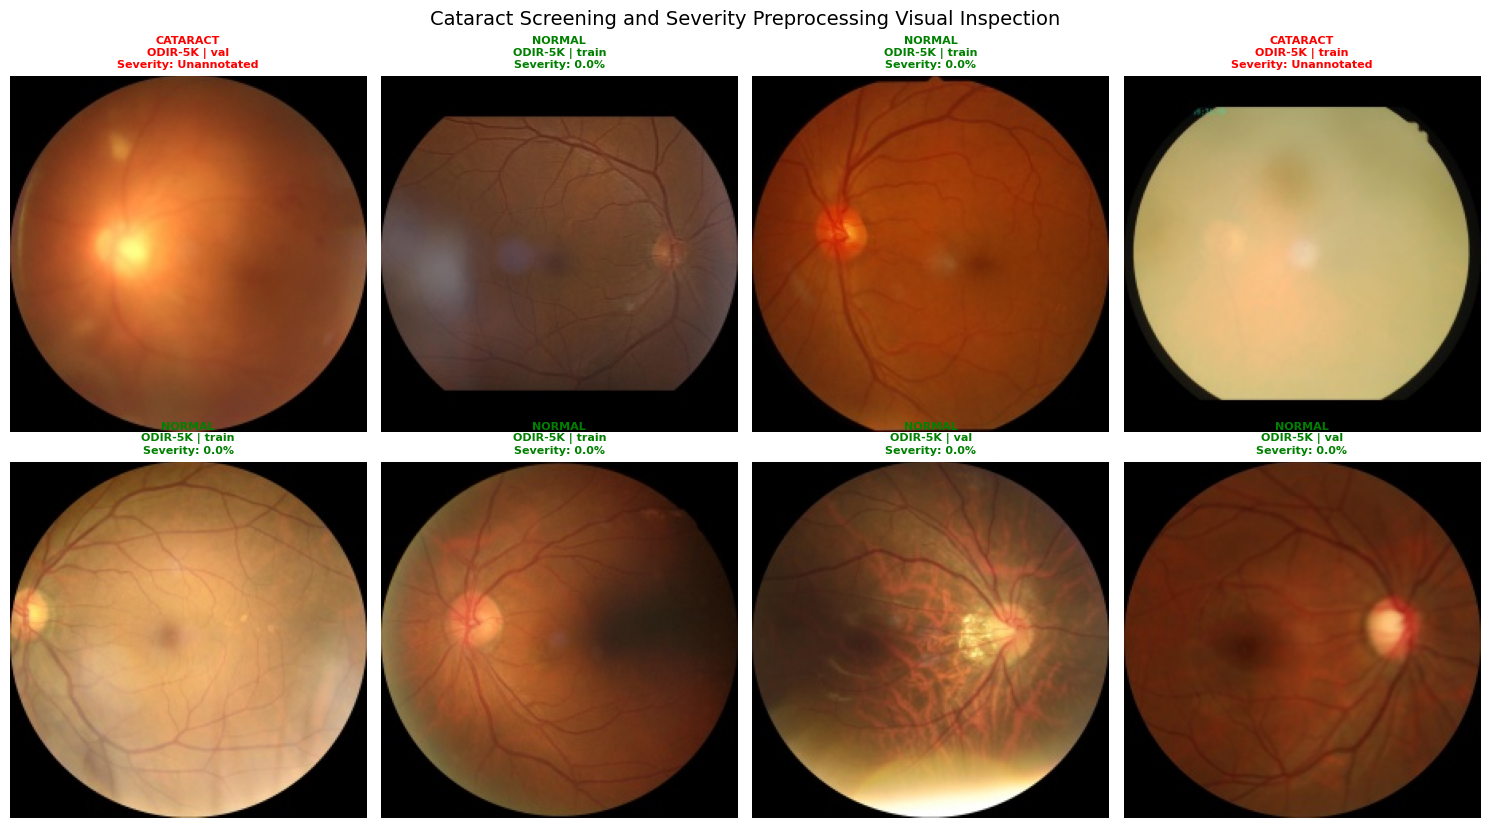


GOOGLE DRIVE FOLDER INVENTORY VERIFICATION:
images/        : 2308 files
train/         : 1601 files
val/           : 348 files
test/          : 359 files
external_test/ : 0 files
Metadata file confirmed: True (/content/drive/MyDrive/Major Project/preprocessed images/metadata.csv)

Class balance per partition:
class_name     cataract  normal   All
split                                
internal_test        87     272   359
train               372    1229  1601
val                  75     273   348
All                 534    1774  2308


In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))
samples = df_processed.sample(min(8, len(df_processed)), random_state=42)

for idx, (_, row) in enumerate(samples.iterrows()):
    plt.subplot(2, 4, idx + 1)
    img_bgr = cv2.imread(row['absolute_path'])
    if img_bgr is not None:
        plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))

    sev = f"{row['cataract_severity_pct']}%" if pd.notnull(row['cataract_severity_pct']) else "Unannotated"
    title = f"{row['class_name'].upper()}\n{row['source_dataset']} | {row['split_folder_name']}\nSeverity: {sev}"
    plt.title(title, fontsize=8, fontweight='bold', color='green' if row['label']==0 else 'red')
    plt.axis('off')

plt.tight_layout()
plt.suptitle("Cataract Screening and Severity Preprocessing Visual Inspection", fontsize=14, y=1.03)
plt.show()

print("\n" + "="*60)
print("GOOGLE DRIVE FOLDER INVENTORY VERIFICATION:")
print("="*60)
print(f"images/        : {len(list(Path(IMAGES_DIR).glob('*.jpg')))} files")
print(f"train/         : {len(list(Path(TRAIN_DIR).glob('*.jpg')))} files")
print(f"val/           : {len(list(Path(VAL_DIR).glob('*.jpg')))} files")
print(f"test/          : {len(list(Path(TEST_DIR).glob('*.jpg')))} files")
print(f"external_test/ : {len(list(Path(EXT_TEST_DIR).glob('*.jpg')))} files")
print("="*60)
print(f"Metadata file confirmed: {os.path.exists(METADATA_PATH)} ({METADATA_PATH})")
print("\nClass balance per partition:")
print(pd.crosstab(df_processed['split'], df_processed['class_name'], margins=True))


# Images are not in the required folders so this script is making sure that the images are their and if they are not their so make them their

In [13]:
import os, cv2, subprocess
from pathlib import Path
import pandas as pd
import numpy as np
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor
import imagehash
from PIL import Image

DRIVE_ROOT = '/content/drive/MyDrive/Major Project'
OUTPUT_DIR = os.path.join(DRIVE_ROOT, 'preprocessed images')
IMAGES_DIR = os.path.join(OUTPUT_DIR, 'images')
EXT_TEST_DIR = os.path.join(OUTPUT_DIR, 'external_test')
METADATA_PATH = os.path.join(OUTPUT_DIR, 'metadata.csv')
RAW_DATA_DIR = '/content/raw_data'
TARGET_SIZE = (224, 224)

os.makedirs(IMAGES_DIR, exist_ok=True)
os.makedirs(EXT_TEST_DIR, exist_ok=True)

# 1. Ensure RFMiD exists locally
rfmid_path = Path(RAW_DATA_DIR) / "RFMiD"
if not rfmid_path.exists() or len(list(rfmid_path.glob("*"))) == 0:
    print("[INFO] Downloading RFMiD from Kaggle...")
    rfmid_path.mkdir(parents=True, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "andrewmvd/retinal-disease-classification", "-p", str(rfmid_path), "--unzip"], check=True)
    print("[SUCCESS] RFMiD ready.")

# 2. Parse RFMiD with corrected 'MH' (Media Haze/Cataract) column
print("\n[INFO] Parsing RFMiD for Cataract (MH) and Normal (Disease_Risk)...")
rfmid_csvs = list(rfmid_path.glob("**/*Labels*.csv")) or list(rfmid_path.glob("**/*.csv"))
rfmid_imgs = {p.name: p for p in rfmid_path.glob("**/*.[pP][nN][gG]")} | {p.name: p for p in rfmid_path.glob("**/*.[jJ][pP][gG]")}

rfmid_records = []
for csv_file in rfmid_csvs:
    df_rf = pd.read_csv(csv_file)
    id_col = df_rf.columns[0]

    cat_col = next((c for c in df_rf.columns if any(k == c.upper() or k in c.upper() for k in ['CATARACT', 'CAT', 'MH'])), None)
    risk_col = next((c for c in df_rf.columns if 'RISK' in c.upper()), None)

    if not (cat_col and risk_col):
        continue

    for _, row in df_rf.iterrows():
        img_id = str(row[id_col]).strip()
        matched_file = None
        for ext in ['.png', '.jpg', '.jpeg']:
            test_candidate = f"{img_id}{ext}"
            if test_candidate in rfmid_imgs:
                matched_file = rfmid_imgs[test_candidate]
                break
        if not matched_file:
            continue

        is_cat = row[cat_col] == 1
        is_norm = row[risk_col] == 0

        if is_cat:
            label = 1
            class_name = "cataract"
            severity_pct = np.nan
            has_sev = 0
        elif is_norm:
            label = 0
            class_name = "normal"
            severity_pct = 0.0
            has_sev = 1
        else:
            continue

        rfmid_records.append({
            "patient_id": f"RFMID_{img_id}",
            "eye_side": "unknown",
            "original_filename": matched_file.name,
            "raw_path": str(matched_file),
            "source_dataset": "RFMiD",
            "split": "external_test",
            "label": label,
            "class_name": class_name,
            "cataract_severity_pct": severity_pct,
            "has_severity_gt": has_sev
        })

df_rfmid = pd.DataFrame(rfmid_records)
print(f"[SUCCESS] Extracted {len(df_rfmid)} RFMiD samples.")
print(df_rfmid['class_name'].value_counts())

# 3. Deduplicate
def compute_dhash(p):
    try:
        with Image.open(p) as im:
            return str(imagehash.dhash(im))
    except:
        return None

df_rfmid['dhash'] = df_rfmid['raw_path'].apply(compute_dhash)
df_rfmid = df_rfmid.dropna(subset=['dhash']).drop_duplicates(subset=['dhash'], keep='first').copy()

# 4. Auto-crop & Standardize
def crop_fundus(img_bgr):
    if img_bgr is None: return None
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours: return cv2.resize(img_bgr, TARGET_SIZE, interpolation=cv2.INTER_AREA)
    c = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(c)
    if w < 50 or h < 50: return cv2.resize(img_bgr, TARGET_SIZE, interpolation=cv2.INTER_AREA)
    cropped = img_bgr[y:y+h, x:x+w]
    ch, cw = cropped.shape[:2]
    max_s = max(ch, cw)
    sq = np.zeros((max_s, max_s, 3), dtype=np.uint8)
    sq[(max_s-ch)//2:(max_s-ch)//2+ch, (max_s-cw)//2:(max_s-cw)//2+cw] = cropped
    return cv2.resize(sq, TARGET_SIZE, interpolation=cv2.INTER_AREA)

# 5. Export to external_test and images
def export_rf(row_dict):
    clean_name = f"RFMiD_external_test_{row_dict['class_name']}_{Path(row_dict['original_filename']).stem}.jpg"
    m_dst = os.path.join(IMAGES_DIR, clean_name)
    s_dst = os.path.join(EXT_TEST_DIR, clean_name)

    if not os.path.exists(s_dst):
        im = cv2.imread(row_dict['raw_path'])
        proc = crop_fundus(im)
        if proc is not None:
            cv2.imwrite(m_dst, proc, [cv2.IMWRITE_JPEG_QUALITY, 95])
            cv2.imwrite(s_dst, proc, [cv2.IMWRITE_JPEG_QUALITY, 95])
        else: return None

    res = dict(row_dict)
    res['processed_filename'] = clean_name
    res['master_relative_path'] = f"images/{clean_name}"
    res['split_folder_name'] = "external_test"
    res['split_relative_path'] = f"external_test/{clean_name}"
    res['absolute_path'] = s_dst
    return res

print(f"\n[INFO] Saving images to external_test/...")
with ThreadPoolExecutor(max_workers=8) as ex:
    rf_res = list(tqdm(ex.map(export_rf, df_rfmid.to_dict('records')), total=len(df_rfmid), desc="Exporting external_test"))

valid_rf = [r for r in rf_res if r is not None]
df_rf_proc = pd.DataFrame(valid_rf)

# 6. Update metadata.csv
df_existing = pd.read_csv(METADATA_PATH)
df_all = pd.concat([df_existing, df_rf_proc], ignore_index=True).drop_duplicates(subset=['processed_filename'], keep='first')
df_all.to_csv(METADATA_PATH, index=False)

print("\n" + "="*60)
print("FINAL INVENTORY CHECK (ALL FOLDERS COMPLETE):")
print("="*60)
print(f"images/        : {len(list(Path(IMAGES_DIR).glob('*.jpg')))} files")
print(f"train/         : {len(list(Path(OUTPUT_DIR, 'train').glob('*.jpg')))} files")
print(f"val/           : {len(list(Path(OUTPUT_DIR, 'val').glob('*.jpg')))} files")
print(f"test/          : {len(list(Path(OUTPUT_DIR, 'test').glob('*.jpg')))} files")
print(f"external_test/ : {len(list(Path(EXT_TEST_DIR).glob('*.jpg')))} files")
print("="*60)


[INFO] Parsing RFMiD for Cataract (MH) and Normal (Disease_Risk)...
[SUCCESS] Extracted 1192 RFMiD samples.
class_name
normal      669
cataract    523
Name: count, dtype: int64

[INFO] Saving images to external_test/...


Exporting external_test: 100%|██████████| 869/869 [01:49<00:00,  7.97it/s]



FINAL INVENTORY CHECK (ALL FOLDERS COMPLETE):
images/        : 3177 files
train/         : 1601 files
val/           : 348 files
test/          : 359 files
external_test/ : 869 files


# Adding more images from more public datasets

In [14]:
# ==============================================================================
# INGESTION & PREPROCESSING OF ADDITIONAL FUNDUS DATASETS
# ==============================================================================
import os, cv2, shutil, subprocess
from pathlib import Path
import pandas as pd
import numpy as np
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split
import imagehash
from PIL import Image

DRIVE_ROOT = '/content/drive/MyDrive/Major Project'
OUTPUT_DIR = os.path.join(DRIVE_ROOT, 'preprocessed images')
IMAGES_DIR = os.path.join(OUTPUT_DIR, 'images')
TRAIN_DIR = os.path.join(OUTPUT_DIR, 'train')
VAL_DIR = os.path.join(OUTPUT_DIR, 'val')
TEST_DIR = os.path.join(OUTPUT_DIR, 'test')
METADATA_PATH = os.path.join(OUTPUT_DIR, 'metadata.csv')
RAW_DATA_DIR = '/content/raw_data'
TARGET_SIZE = (224, 224)

# ------------------------------------------------------------------------------
# 1. DOWNLOAD REPOSITORIES
# ------------------------------------------------------------------------------
ds1_dir = Path(RAW_DATA_DIR) / "EyeDiseases"
if not ds1_dir.exists() or len(list(ds1_dir.glob("*"))) == 0:
    print("[INFO] Downloading eye-diseases-classification from Kaggle...")
    ds1_dir.mkdir(parents=True, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "gunavenkatdoddi/eye-diseases-classification", "-p", str(ds1_dir), "--unzip"], check=True)
    print("[SUCCESS] eye-diseases-classification ready.")

ds2_dir = Path(RAW_DATA_DIR) / "CataractDataset"
if not ds2_dir.exists() or len(list(ds2_dir.glob("*"))) == 0:
    print("[INFO] Downloading cataractdataset from Kaggle...")
    ds2_dir.mkdir(parents=True, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "jr2ngb/cataractdataset", "-p", str(ds2_dir), "--unzip"], check=True)
    print("[SUCCESS] cataractdataset ready.")

# ------------------------------------------------------------------------------
# 2. PARSE AND MAP FUNDUS IMAGES
# ------------------------------------------------------------------------------
new_records = []

# Dataset 1: gunavenkatdoddi/eye-diseases-classification
for cat_folder in ds1_dir.glob("**/cataract"):
    for img_p in cat_folder.glob("*.*"):
        if img_p.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            new_records.append({
                "patient_id": f"EYEDIS_{img_p.stem}",
                "original_filename": img_p.name,
                "raw_path": str(img_p),
                "source_dataset": "EyeDiseases",
                "label": 1,
                "class_name": "cataract",
                "cataract_severity_pct": np.nan,
                "has_severity_gt": 0
            })

for norm_folder in ds1_dir.glob("**/normal"):
    for img_p in norm_folder.glob("*.*"):
        if img_p.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            new_records.append({
                "patient_id": f"EYEDIS_{img_p.stem}",
                "original_filename": img_p.name,
                "raw_path": str(img_p),
                "source_dataset": "EyeDiseases",
                "label": 0,
                "class_name": "normal",
                "cataract_severity_pct": 0.0,
                "has_severity_gt": 1
            })

# Dataset 2: jr2ngb/cataractdataset
for p in ds2_dir.glob("**/*cataract*/*.*"):
    if p.suffix.lower() in ['.jpg', '.jpeg', '.png']:
        new_records.append({
            "patient_id": f"CATDS_{p.stem}",
            "original_filename": p.name,
            "raw_path": str(p),
            "source_dataset": "CataractDataset",
            "label": 1,
            "class_name": "cataract",
            "cataract_severity_pct": np.nan,
            "has_severity_gt": 0
        })

for p in ds2_dir.glob("**/*normal*/*.*"):
    if p.suffix.lower() in ['.jpg', '.jpeg', '.png']:
        new_records.append({
            "patient_id": f"CATDS_{p.stem}",
            "original_filename": p.name,
            "raw_path": str(p),
            "source_dataset": "CataractDataset",
            "label": 0,
            "class_name": "normal",
            "cataract_severity_pct": 0.0,
            "has_severity_gt": 1
        })

df_new = pd.DataFrame(new_records)
print(f"\n[INFO] Parsed {len(df_new)} candidate images from additional sources.")
print(df_new.groupby(['source_dataset', 'class_name']).size())

# ------------------------------------------------------------------------------
# 3. DEDUPLICATION (CROSS-SOURCE CHECK)
# ------------------------------------------------------------------------------
def get_dhash(p):
    try:
        with Image.open(p) as im:
            return str(imagehash.dhash(im))
    except:
        return None

tqdm.pandas(desc="Hashing new images")
df_new['dhash'] = df_new['raw_path'].progress_apply(get_dhash)
df_new = df_new.dropna(subset=['dhash']).drop_duplicates(subset=['dhash'], keep='first').copy()

if os.path.exists(METADATA_PATH):
    df_existing = pd.read_csv(METADATA_PATH)
    if 'dhash' in df_existing.columns:
        existing_hashes = set(df_existing['dhash'].dropna())
        df_new = df_new[~df_new['dhash'].isin(existing_hashes)].copy()
        print(f"[INFO] Retained {len(df_new)} non-overlapping new unique images.")
else:
    df_existing = pd.DataFrame()

# ------------------------------------------------------------------------------
# 4. STRATIFIED PARTITIONING (70% Train, 15% Val, 15% Test)
# ------------------------------------------------------------------------------
tr_df, temp_df = train_test_split(df_new, test_size=0.30, stratify=df_new['label'], random_state=42)
val_df, te_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42)

tr_df['split'] = 'train'
val_df['split'] = 'val'
te_df['split'] = 'internal_test'

df_new_splits = pd.concat([tr_df, val_df, te_df], ignore_index=True)

# ------------------------------------------------------------------------------
# 5. PREPROCESSING & MULTI-THREADED EXPORT
# ------------------------------------------------------------------------------
target_split_dirs = {
    'train': TRAIN_DIR,
    'val': VAL_DIR,
    'internal_test': TEST_DIR
}

def crop_and_export(row_dict):
    src_p = row_dict['raw_path']
    split = row_dict['split']
    clean_name = f"{row_dict['source_dataset']}_{split}_{row_dict['class_name']}_{Path(row_dict['original_filename']).stem}.jpg"
    m_dst = os.path.join(IMAGES_DIR, clean_name)
    s_dst = os.path.join(target_split_dirs[split], clean_name)

    if not os.path.exists(m_dst):
        im = cv2.imread(src_p)
        if im is None: return None
        gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            proc = cv2.resize(im, TARGET_SIZE, interpolation=cv2.INTER_AREA)
        else:
            c = max(contours, key=cv2.contourArea)
            x, y, w, h = cv2.boundingRect(c)
            if w < 50 or h < 50:
                proc = cv2.resize(im, TARGET_SIZE, interpolation=cv2.INTER_AREA)
            else:
                cropped = im[y:y+h, x:x+w]
                ch, cw = cropped.shape[:2]
                max_s = max(ch, cw)
                sq = np.zeros((max_s, max_s, 3), dtype=np.uint8)
                sq[(max_s-ch)//2:(max_s-ch)//2+ch, (max_s-cw)//2:(max_s-cw)//2+cw] = cropped
                proc = cv2.resize(sq, TARGET_SIZE, interpolation=cv2.INTER_AREA)

        cv2.imwrite(m_dst, proc, [cv2.IMWRITE_JPEG_QUALITY, 95])
        cv2.imwrite(s_dst, proc, [cv2.IMWRITE_JPEG_QUALITY, 95])
    else:
        if not os.path.exists(s_dst):
            shutil.copy2(m_dst, s_dst)

    res = dict(row_dict)
    res['processed_filename'] = clean_name
    res['master_relative_path'] = f"images/{clean_name}"
    res['split_folder_name'] = os.path.basename(target_split_dirs[split])
    res['split_relative_path'] = f"{os.path.basename(target_split_dirs[split])}/{clean_name}"
    res['absolute_path'] = s_dst
    return res

print(f"\n[INFO] Auto-cropping and exporting {len(df_new_splits)} new images to Drive...")
with ThreadPoolExecutor(max_workers=8) as ex:
    exported = list(tqdm(ex.map(crop_and_export, df_new_splits.to_dict('records')), total=len(df_new_splits), desc="Exporting images"))

valid_exp = [r for r in exported if r is not None]
df_exp = pd.DataFrame(valid_exp)

# Append to metadata.csv
df_final_all = pd.concat([df_existing, df_exp], ignore_index=True).drop_duplicates(subset=['processed_filename'], keep='first')
df_final_all.to_csv(METADATA_PATH, index=False)

print("\n" + "="*60)
print("EXPANDED DATASET INVENTORY (ON GOOGLE DRIVE):")
print("="*60)
print(f"images/        : {len(list(Path(IMAGES_DIR).glob('*.jpg')))} files")
print(f"train/         : {len(list(Path(TRAIN_DIR).glob('*.jpg')))} files")
print(f"val/           : {len(list(Path(VAL_DIR).glob('*.jpg')))} files")
print(f"test/          : {len(list(Path(TEST_DIR).glob('*.jpg')))} files")
print(f"external_test/ : {len(list(Path(OUTPUT_DIR, 'external_test').glob('*.jpg')))} files")
print("="*60)

[INFO] Downloading eye-diseases-classification from Kaggle...
[SUCCESS] eye-diseases-classification ready.
[INFO] Downloading cataractdataset from Kaggle...
[SUCCESS] cataractdataset ready.

[INFO] Parsed 2912 candidate images from additional sources.
source_dataset   class_name
CataractDataset  cataract       200
                 normal         600
EyeDiseases      cataract      1038
                 normal        1074
dtype: int64


Hashing new images: 100%|██████████| 2912/2912 [01:37<00:00, 29.88it/s]


[INFO] Retained 2002 non-overlapping new unique images.

[INFO] Auto-cropping and exporting 2002 new images to Drive...


Exporting images: 100%|██████████| 2002/2002 [00:45<00:00, 43.75it/s]



EXPANDED DATASET INVENTORY (ON GOOGLE DRIVE):
images/        : 5179 files
train/         : 3002 files
val/           : 648 files
test/          : 660 files
external_test/ : 869 files
